# Лекция 11: Компьютерное зрение
## Адаптеры в диффузионных моделях & SOTA модели. Часть 1

**Преподаватель:** Шевченко Елена, Т-Банк

**Аудитория:** ФКН ВШЭ, МФТИ

---

## Содержание

1. **Адаптеры** (этот ноутбук)
   1. Зачем нужны, типы адаптеров
   2. ControlNet
   3. IP-Adapter
   4. InstantStyle: инъекция по блокам
   5. Что ещё бывает
   6. От адаптеров к in-context conditioning
2. Как устроена современная text-to-image модель
3. Современные модели: FLUX и Qwen-Image
4. Дистилляция

---

# I. Адаптеры в диффузионных моделях

## 1. Зачем нужны и какие бывают

Помимо текста нужно условие (conditioning) в виде изображения: контуры (Canny edges), глубина, поза (keypoints), маска сегментации, стилевой референс. LoRA (прошлая лекция) меняет только веса и нового входа не даёт.

- **Новый вход + дообучение всей сети** (например, конкатенация условия с латентом): дорого, риск потерять качество text2img, под каждый тип условия своя модель.
- **Адаптер**: основная сеть заморожена, обучается небольшой модуль, который встраивает условие в её промежуточные признаки. Text2img не деградирует, обучение дешёвое, адаптеры подключаются и отключаются на inference.

| Тип контроля | Что задаёт | Информация | Базовый метод |
|---|---|---|---|
| Структурный | где что находится: поза, края, глубина, маска | пространственно-локальная | ControlNet |
| Семантический / стилевой | как выглядит: стиль, внешность, объект | глобальная | IP-Adapter |

---

## 2. ControlNet

> Zhang et al., "Adding Conditional Control to Text-to-Image Diffusion Models", CVPR 2023

### 2.1 Ключевая идея

Часть основной сети (для U-Net в SD — encoder и middle block) копируется; оригинал заморожен, копия учится принимать условие. Выходы копии прибавляются к признакам основной сети через **zero convolutions** — свёртки 1×1 с нулевой инициализацией (п. 2.4).

### 2.2 Формальное описание

Для блока сети $\mathcal{F}(\cdot;\Theta)$: без условия $y = \mathcal{F}(x;\Theta)$, с ControlNet

$$y_{c} = \underbrace{\mathcal{F}(x; \Theta)}_{\text{заморожено}} + \mathcal{Z}\!\left(\underbrace{\mathcal{F}\!\left(x + \mathcal{Z}(c;\, \Theta_{z1});\, \Theta_c\right)}_{\text{обучаемая копия}};\, \Theta_{z2}\right)$$

где $\Theta$ — замороженные параметры, $\Theta_c$ — параметры копии (инициализированы из $\Theta$), $\Theta_{z1}, \Theta_{z2}$ — zero convolutions на входе и выходе копии, $c$ — условие (Canny, глубина, поза, ...).

### 2.3 Разбор на SD U-Net

![controlnet](assets/controlnet.png)

1. Основная сеть заморожена; encoder и middle block копируются вместе с весами и обучаются.
2. **Conditioning encoder** $\mathcal{E}$ — небольшая свёрточная сеть: переводит условие $c_i$ (например, canny-карту 512×512) в разрешение латента 64×64, $c_f = \mathcal{E}(c_i)$. В статье — 4 слоя 4×4 со stride 2, в коде diffusers — 8 свёрток, из них 3 со stride 2 (512 → 64).
3. На каждом шаге основная сеть получает латент $z_t$, шаг $t$ и текст $c_t$. Копия получает то же самое плюс условие: $z_t + \mathcal{Z}(c_f;\Theta_{z1})$. Выходы блоков ControlNet прибавляются к входам соответствующих блоков decoder'а.

### 2.4 Zero convolutions

Активации необученной копии не согласованы с основной сетью и портят text2img. Поэтому выход копии проходит через

$$\mathcal{Z}(h;\Theta_z) = W_z h + b_z, \quad W_z = 0,\ b_z = 0.$$

- На первом шаге $\mathcal{Z} = 0$: модель работает как исходная text2img.
- Обучение не блокируется: $\partial \mathcal{Z}/\partial W_z = h \neq 0$, и $W_z$ обновляется с первого шага. Градиент в копию ($\partial \mathcal{Z}/\partial h = W_z$) появляется после первых обновлений, вклад ControlNet растёт постепенно.

**Внезапная сходимость** (sudden convergence): модель долго не следует условию, затем резко начинает.

![phenomen](assets/conv_phenomen.png)

### 2.5 Функция потерь

$$\mathcal{L} = \mathbb{E}_{z_0, t, c_t, c_f, \epsilon \sim \mathcal{N}(0,I)}\left[\left\|\epsilon - \epsilon_{\theta}(z_t, t, c_t, c_f)\right\|_2^2\right]$$

$c_t$ — промпт, $c_f$ — структурное условие. Обучение устойчиво даже на небольших датасетах (<50k пар) и по скорости сопоставимо с файнтюнингом всей модели.

### 2.6 ControlNet и CFG
**CFG:** $ \epsilon = \epsilon_{uc} + g(\epsilon_{c} - \epsilon_{uc}) $

**Проблема:** при использовании Classifier-Free Guidance на каждом шаге делается **два forward pass**: условный (с промптом) и безусловный (с пустым промптом).

Вопрос: к каким из двух pass'ов применять ControlNet?

| Вариант | Поведение |
|---|---|
| Только к **conditional** | Очень жёсткое следование условию при высоком CFG scale |
| К **обоим** | Без промпта условный и безусловный pass совпадают ($\epsilon_c = \epsilon_{uc}$) — CFG перестаёт работать, картинка блёклая |


![cfg1](assets/cfg.png)

**Решение авторов:** применять ControlNet **только к conditional pass**, но при этом **перевзвешивать влияние по блокам** в зависимости от пространственного разрешения:

$$w_i = \frac{64}{h_i}, \quad h_i \in \{8, 16, 32, 64\}$$

где $h_i$ — пространственный размер feature map блока $i$.

```
Блоки с низким разрешением (семантика, h=8):
  w = 64/8 = 8  → большой вес, сильное влияние
  
Блоки с высоким разрешением (детали, h=64):
  w = 64/64 = 1 → малый вес, слабое влияние
```

Смысл: при больших CFG scale структурные условия из семантических блоков важнее, а детали генерации не должны быть жёстко привязаны к условию.

![cfg_g1](assets/cfg_good.png)

### 2.7 Типы условий

В ControlNet 1.1 под каждый тип условия обучена отдельная модель:
- **структурные:** Canny, HED / Scribble (скетчи), MLSD (прямые линии), Depth, Normal;
- **семантические:** Segmentation (ADE20k / COCO);
- **human-centric:** OpenPose, DWPose;
- **прочие:** Inpaint, Shuffle / IP2P, Tile (upscaling).

Демо ниже: Canny из референса + промпт.

---

In [1]:
!git clone --depth 1 --branch lesson_11 --filter=blob:none --sparse https://github.com/T-CV/cv-course-at-mipt-fall-2026.git repo
!cd repo && git sparse-checkout set lesson_11/assets
!cp -r repo/lesson_11/assets ./assets

Cloning into 'repo'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 40 (delta 0), reused 33 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 12.15 KiB | 3.04 MiB/s, done.
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 0), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), 10.92 KiB | 3.64 MiB/s, done.
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 47 (delta 0), reused 47 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 35.94 MiB | 14.71 MiB/s, done.
Updating files: 100% (47/47), done.


In [ ]:
import torch
import numpy as np
from PIL import Image
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
from diffusers.utils import load_image
import cv2
from matplotlib import pyplot as plt
%matplotlib inline

# Загружаем ControlNet + pipeline
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16
).to("cuda")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/opt/conda/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


  0%|          | 0/30 [00:00<?, ?it/s]

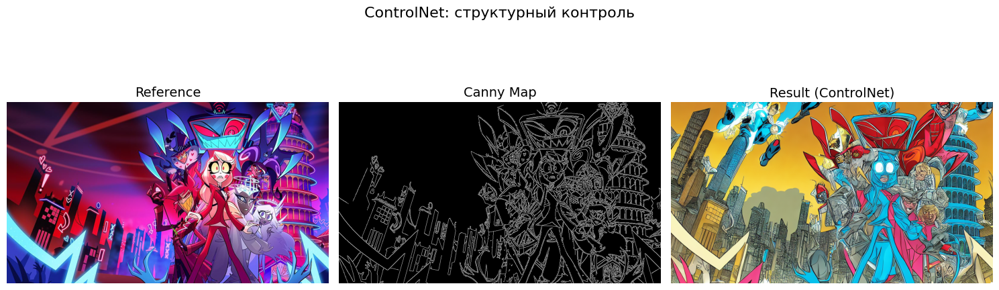

In [ ]:
# Загружаем референс
reference = load_image("assets/hazbin.jpg")
reference_np = np.array(reference)

# Извлекаем структуру — Canny edges
def extract_canny(image_np: np.ndarray, low: int = 100, high: int = 200) -> Image.Image:
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, low, high)
    # ControlNet ожидает RGB
    edges_rgb = np.stack([edges] * 3, axis=-1)
    return Image.fromarray(edges_rgb)

canny_map = extract_canny(reference_np)

# Генерируем — структура берется с картинки, стиль можем задать сами
result_structural = pipe(
    prompt="city of future, superheros, colorful, comic style",
    negative_prompt="blurry, low quality",
    image=canny_map,
    num_inference_steps=30,
    controlnet_conditioning_scale=1.0,  # сила следования структуре
    guidance_scale=7.5,
    height=512, width=896,  # референс 1080×608: берём близкое к нему разрешение, кратное 8
    generator=torch.Generator("cuda").manual_seed(42),
).images[0]

# --- Визуализация ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(reference)
axes[0].set_title("Reference", fontsize=14)
axes[0].axis("off")

axes[1].imshow(canny_map)
axes[1].set_title("Canny Map", fontsize=14)
axes[1].axis("off")

axes[2].imshow(result_structural)
axes[2].set_title("Result (ControlNet)", fontsize=14)
axes[2].axis("off")

plt.suptitle("ControlNet: структурный контроль", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("step1_structural_grid.png", bbox_inches="tight")
plt.show()

## 3. IP-Adapter

> Ye et al., "IP-Adapter: Text Compatible Image Prompt Adapter for Text-to-Image Diffusion Models", Tencent AI Lab, 2023

![ip_adapter](assets/ip_adapter_general.png)

### 3.1 Мотивация

Как передать "изображение-референс" в диффузионную модель, не теряя совместимости с текстом?

```
прямые методы:
  image-to-image: через шум.
    → меняет структуру вместе со стилем.
    → нет точного управления "насколько" следовать референсу.
    
  fine-tuning (DreamBooth / Textual Inversion):  
    → дообучение на каждую сущность (обычно 3–5 изображений).
    → DreamBooth — отдельная модель под каждый объект.
    → Textual Inversion — только новый эмбеддинг слова, но внешность передаёт хуже.
```

Цель IP-Adapter: легковесный адаптер (~22M параметров), который:  
- Принимает одно изображение-референс
- Работает параллельно с текстом (не вместо него)
- Совместим с любыми файнтюненными версиями базовой модели
- Совместим с ControlNet (структурный + семантический контроль одновременно)

### 3.2 Decoupled cross-attention

![dec_attn](assets/decoupled-attention.png)

В обычном cross-attention U-Net признаки картинки $h$ «спрашивают» текст: запрос берётся из $h$, ключи и значения — из текстовых токенов $c_t$. IP-Adapter добавляет **второй такой же attention для картинки-референса** и складывает результаты.

**Обозначения:**
- $h$ — признаки латента в текущем блоке U-Net (вход слоя);
- $c_t$ — текстовые токены (из CLIP text encoder);
- $c_i$ — image-токены референса (CLIP image encoder → image projection).

**Шаг 1. Запрос — общий для обеих веток:**
$$Q = h W_q$$

**Шаг 2. Текстовая ветка** — как в исходной SD, веса заморожены:
$$\text{out}_{text} = \mathrm{softmax}\!\left(\frac{Q\,(c_t W_k)^\top}{\sqrt d}\right) c_t W_v$$

**Шаг 3. Image-ветка** — те же формулы, но свои **новые обучаемые** $W'_k, W'_v$:
$$\text{out}_{img} = \mathrm{softmax}\!\left(\frac{Q\,(c_i W'_k)^\top}{\sqrt d}\right) c_i W'_v$$

**Шаг 4. Сумма:**
$$\text{out} = \text{out}_{text} + \lambda\, \text{out}_{img}$$

$\lambda$ (`scale` / `ip_adapter_scale` в коде) — сила image prompt; при $\lambda = 0$ модель совпадает с исходной.

Заморожены основная сеть (U-Net/DiT) и оба CLIP-энкодера; обучаются (~22M) только image projection и $W'_k, W'_v$ в каждом блоке.

### 3.3 Image encoder: CLIP ViT

Референс кодируется замороженным CLIP ViT (ViT-H/14 или ViT-L/14); обучаемая image projection переводит выход в $N_q$ image-токенов.

| Вариант | Вход → проекция | Особенности |
|---|---|---|
| IP-Adapter | глобальный embedding CLIP → Linear | быстро, общая семантика |
| IP-Adapter Plus | патч-эмбеддинги CLIP → Perceiver Resampler (обучаемые query + cross-attention) | точнее детали и текстуры |

Демо InstantStyle (раздел 4) использует веса Plus (`ip-adapter-plus_sdxl_vit-h.bin`).

### 3.4 Обучение

~10M пар изображение–текст (LAION и аналоги); одно изображение — и условие, и таргет.

1. Пара $(x_0, c_t)$, $z_0$ — латент $x_0$; $c_i = \mathrm{proj}(\mathrm{CLIP}_{img}(x_0))$.
2. $z_t = \sqrt{\bar\alpha_t}\, z_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, $\;\mathcal{L} = \mathbb{E}\left[\|\epsilon - \epsilon_\theta(z_t, t, c_t, c_i)\|_2^2\right]$.
3. Обновляются только image projection и $W'_k, W'_v$.

Для CFG текст и image embedding при обучении случайно заменяются на пустую строку и нули соответственно. На inference: $\lambda = 1.0$ — доминирует изображение, $0.5$ — баланс, $0.2$ — доминирует текст.

### 3.5 Применение

- **Style reference:** картина + «cat» → кот в стиле картины.
- **Subject reference:** фото сумки + «photo on beach» → эта сумка на пляже.
- **Вместе с ControlNet:** ControlNet задаёт расположение (например, поза), IP-Adapter — внешний вид.

Демо ниже: SD 1.5, `scale=0.3` и `scale=0.7`.

---

In [5]:
!pip install torch diffusers

In [6]:
import gc
from diffusers import StableDiffusionPipeline

# Освобождаем память от ControlNet-пайплайна
del pipe, controlnet
gc.collect()
torch.cuda.empty_cache()

# Базовый pipeline (без ControlNet)
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
).to("cuda")

# Подключаем IP-Adapter: веса адаптера и CLIP ViT-H image encoder
# скачиваются из h94/IP-Adapter (models/ и models/image_encoder/)
pipe.load_ip_adapter(
    "h94/IP-Adapter",
    subfolder="models",
    weight_name="ip-adapter_sd15.bin",
)

  0%|          | 0/30 [00:00<?, ?it/s]

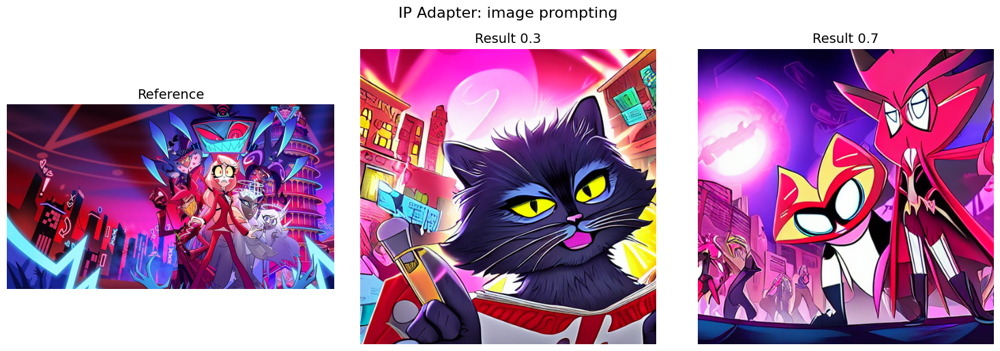

In [ ]:
# Стилевой референс — картина
style_reference = Image.open("assets/hazbin.jpg")

# Генерируем с переносом стиля
def ip_generate(scale: float, seed: int = 42) -> Image.Image:
    pipe.set_ip_adapter_scale(scale)  # сила влияния image prompt (λ)
    return pipe(
        prompt="fluffy cat",
        negative_prompt="blurry, low quality",
        ip_adapter_image=style_reference,
        num_inference_steps=30,
        generator=torch.Generator("cuda").manual_seed(seed),
    ).images[0]

result_style03 = ip_generate(0.3)
result_style07 = ip_generate(0.7)

# --- Визуализация ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(style_reference)
axes[0].set_title("Reference", fontsize=14)
axes[0].axis("off")

axes[1].imshow(result_style03)
axes[1].set_title("Result 0.3", fontsize=14)
axes[1].axis("off")

axes[2].imshow(result_style07)
axes[2].set_title("Result 0.7", fontsize=14)
axes[2].axis("off")

plt.suptitle("IP Adapter: image prompting", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("step2_ip_adapter_grid.png", bbox_inches="tight")
plt.show()

## 4. InstantStyle: инъекция по блокам

> Wang et al., "InstantStyle: Free Lunch towards Style-Preserving in Text-to-Image Generation", arXiv:2404.02733

![inst_style](assets/inst_style.png)

**Проблема IP-Adapter:** CLIP embedding смешивает стиль и контент. Референс — Ван Гог с подсолнухами, промпт «a cat»: переносится стиль, но и подсолнухи (content leakage).

**Наблюдения:** (1) одни блоки U-Net отвечают за layout и контент, другие — за цвета, текстуры, стиль; (2) разность image embedding и эмбеддинга контента содержит в основном стиль.

**Два изменения:**
1. **Инъекция только в стилевые блоки.** Базовый IP-Adapter добавляет image-ветку (токены $c_i$) во все cross-attention слои и переносит стиль, контент и layout. InstantStyle оставляет image-ветку только в стилевых блоках, в остальных $\lambda = 0$.
2. **Вычитание контента (опционально):** $e_{style} = e_{img} - e_{content}$, где $e_{img} = \mathrm{CLIP}_{img}(\text{референс})$, $e_{content} = \mathrm{CLIP}_{text}(\text{описание контента референса})$.

**Ничего не обучается:** веса IP-Adapter готовые, меняются только блоки инъекции и embedding («free lunch»). Результат: кот в стиле Ван Гога без подсолнухов.

### Блоки SDXL в демо

В коде ниже (SDXL + IP-Adapter Plus) два «полюса»:

| Константа | Блоки | Что переносится |
|---|---|---|
| `STYLE_BLOCKS` | `up_blocks.0.attentions.1` | стиль: цвета, текстуры |
| `CONTEXT_BLOCKS` | `down_blocks.2.attentions.1` | контекст: layout и объекты референса |

`set_block_scales` задаёт $\lambda$ по подстроке имени блока, прочим — $\lambda = 0$. Эксперименты: все блоки; только стиль; только контекст; две комбинации с $\lambda \in \{1.0, 0.5\}$. Вычитание контента в демо не используется.

**Больше стиля** — инъекция в стилевые блоки:

![style](assets/img_prompt.png)

**Больше контекста** — инъекция в контекстные блоки:

![obj](assets/img_prompt_i2i_field.png)


Загрузка pipeline...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


... (12 outputs left out)

  → Стиль + контекст style=1.0 / context=0.5


  0%|          | 0/30 [00:00<?, ?it/s]

  → Стиль + контекст style=0.5 / context=1.0


  0%|          | 0/30 [00:00<?, ?it/s]

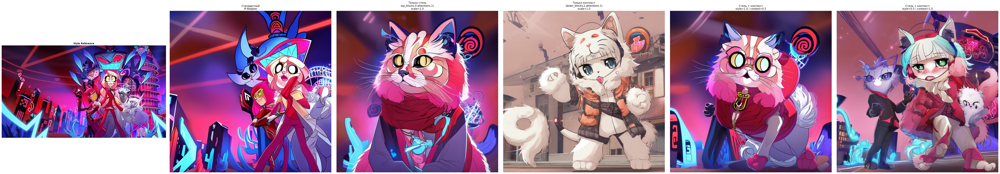

In [14]:
import gc
import torch
from PIL import Image
from diffusers import StableDiffusionXLPipeline, AutoencoderKL
from diffusers.models.attention_processor import IPAdapterAttnProcessor2_0
from transformers import CLIPVisionModelWithProjection
import matplotlib.pyplot as plt


# ── константы ─────────────────────────────────────────────────────────────────
# Как в статье InstantStyle: по одному transformer-блоку внутри up_blocks.0 и down_blocks.2
STYLE_BLOCKS   = ["up_blocks.0.attentions.1"]
CONTEXT_BLOCKS = ["down_blocks.2.attentions.1"]

BIG_SCALE   = 1.0
SMALL_SCALE = 0.5

PROMPT          = "fluffy cat"
NEGATIVE_PROMPT = "blurry, low quality, ugly"
SEED            = 42


# ── загрузка ──────────────────────────────────────────────────────────────────
# # Освобождаем память от SD 1.5, иначе на T4 не хватит места под SDXL
# del pipe
gc.collect()
torch.cuda.empty_cache()

print("Загрузка pipeline...")
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    vae=vae, torch_dtype=torch.float16, use_safetensors=True,
).to("cuda")

print("Загрузка IP-Adapter...")
pipe.load_ip_adapter(
    "h94/IP-Adapter",
    subfolder="sdxl_models",
    weight_name="ip-adapter-plus_sdxl_vit-h.bin",
    image_encoder_folder="models/image_encoder",  # ViT-H без текстовой части
)
pipe.set_ip_adapter_scale(1.0)


# ── проверка блоков ───────────────────────────────────────────────────────────
def get_all_ip_block_names(pipe):
    return sorted([
        name for name, module in pipe.unet.named_modules()
        if isinstance(getattr(module, "processor", None), IPAdapterAttnProcessor2_0)
    ])


def check_blocks(pipe, style_blocks, context_blocks):
    all_blocks = get_all_ip_block_names(pipe)

    print(f"\nВсего IP-Adapter блоков: {len(all_blocks)}")

    # проверяем что заданные блоки реально существуют
    for label, blocks in [("STYLE", style_blocks), ("CONTEXT", context_blocks)]:
        matched = [b for b in all_blocks if any(sb in b for sb in blocks)]
        print(f"\n{label}_BLOCKS → совпадений: {len(matched)}")
        for name in matched:
            print(f"  ✓ {name}")

    # блоки которые не попадают ни в стиль ни в контекст
    uncovered = [
        b for b in all_blocks
        if not any(sb in b for sb in style_blocks + context_blocks)
    ]
    print(f"\nНепокрытые блоки: {len(uncovered)}")
    for name in uncovered[:5]:
        print(f"  - {name}")
    if len(uncovered) > 5:
        print(f"  ... и ещё {len(uncovered) - 5}")


check_blocks(pipe, STYLE_BLOCKS, CONTEXT_BLOCKS)


# ── управление scale ──────────────────────────────────────────────────────────
def set_block_scales(pipe, config: dict):
    """
    config: { "подстрока_блока": scale, ... }
    блоки не попавшие ни в одну подстроку → scale=0.0
    """
    for name, module in pipe.unet.named_modules():
        proc = getattr(module, "processor", None)
        if isinstance(proc, IPAdapterAttnProcessor2_0):
            scale = 0.0
            for block_pattern, block_scale in config.items():
                if block_pattern in name:
                    scale = block_scale
                    break
            proc.scale = [scale]


# ── генерация ─────────────────────────────────────────────────────────────────
def generate(scale_config=None, seed=SEED):
    """
    scale_config=None → стандартный ip-adapter (все блоки, scale=1.0)
    scale_config={}   → кастомные scale по блокам
    """
    if scale_config is None:
        pipe.set_ip_adapter_scale(1.0)
    else:
        set_block_scales(pipe, scale_config)

    return pipe(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        ip_adapter_image=style_reference,
        guidance_scale=5.0,
        num_inference_steps=30,
        generator=torch.Generator("cuda").manual_seed(seed),
    ).images[0]


# ── эксперименты ──────────────────────────────────────────────────────────────
style_reference = Image.open("assets/hazbin.jpg")

experiments = [
    (
        "Стандартный\nIP-Adapter",
        None,
    ),
    (
        f"Только стиль\n({', '.join(STYLE_BLOCKS)})\nscale={BIG_SCALE}",
        {b: BIG_SCALE for b in STYLE_BLOCKS},
    ),
    (
        f"Только контекст\n({', '.join(CONTEXT_BLOCKS)})\nscale={BIG_SCALE}",
        {b: BIG_SCALE for b in CONTEXT_BLOCKS},
    ),
    (
        f"Стиль + контекст\nstyle={BIG_SCALE} / context={SMALL_SCALE}",
        {**{b: BIG_SCALE for b in STYLE_BLOCKS},
         **{b: SMALL_SCALE for b in CONTEXT_BLOCKS}},
    ),
    (
        f"Стиль + контекст\nstyle={SMALL_SCALE} / context={BIG_SCALE}",
        {**{b: SMALL_SCALE for b in STYLE_BLOCKS},
         **{b: BIG_SCALE for b in CONTEXT_BLOCKS}},
    ),
]

print("\nГенерация:")
results = []
for title, config in experiments:
    print(f"  → {title.replace(chr(10), ' ')}")
    results.append((title, generate(scale_config=config)))


# ── визуализация ──────────────────────────────────────────────────────────────
n = len(results) + 1
fig, axes = plt.subplots(1, n, figsize=(10 * n, 10))

axes[0].imshow(style_reference)
axes[0].set_title("Style Reference", fontsize=10, fontweight="bold")
axes[0].axis("off")

for ax, (title, img) in zip(axes[1:], results):
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Что ещё бывает

| Метод | Что меняет относительно базового ControlNet / IP-Adapter | Год |
|---|---|---|
| ControlNet++ | cycle consistency loss: условие, извлечённое reward-моделью из одношагового деноизинга, сравнивается со входным | 2024 |
| ControlNeXt | лёгкая свёрточная сеть вместо копии encoder'а; Cross Normalization вместо zero conv; частичное дообучение основной сети | 2024 |
| ControlNet Tile | условие — размытый тайл; super-resolution с тайлингом и MultiDiffusion | 2023 |
| StableSR | SR на SD 1.5: признаки low-res изображения встраиваются в сеть (feature injection) | 2023 |
| SeeSR | SR на SD2: DAPE извлекает из деградированного изображения теги и семантические промпты | 2024 |
| SUPIR | SR на SDXL: LQ encoder для деградированного изображения, промпт генерирует LLaVA | 2024 |
| Jasper Upscaler | ControlNet для FLUX.1-dev на синтетических деградациях, без тайлинга | 2024 |
| IP-Adapter Plus | Perceiver Resampler по патч-эмбеддингам CLIP вместо Linear; Plus Face — на кропе лица | 2023 |
| IP-Adapter FaceID | face recognition (InsightFace / ArcFace, 512-dim) вместо CLIP; Plus v2 добавляет CLIP-эмбеддинг лица и LoRA | 2023 |
| InstantID | IP-Adapter по face embedding + IdentityNet (ControlNet по 5 точкам лица); SDXL заморожена | 2024 |
| PhotoMaker | identity из нескольких фото: их CLIP-эмбеддинги сливаются с эмбеддингом слова класса в промпте (stacked ID embedding); энкодер и LoRA обучены один раз, дообучать под человека не нужно | 2024 |
| StyleAligned | shared attention между изображениями одной генерации; без style encoder и обучения | 2024 |

## 6. От адаптеров к in-context conditioning

**Идея:** в новых моделях референс не подают через отдельный модуль, а просто добавляют его токены в ту же последовательность, которую обрабатывает трансформер.

**Как было (U-Net + адаптеры):**
- ControlNet — отдельная копия энкодера, её признаки **прибавляются** к признакам U-Net;
- IP-Adapter — отдельный **cross-attention** на image-токены референса;
- на каждый тип условия нужен свой обученный модуль.

**Как стало (MM-DiT, лекция 11-2):**
- текст и картинка уже идут **одной последовательностью токенов** через общий attention;
- референс кодируется **тем же VAE**, что и генерируемая картинка, и его токены дописываются в конец:

```
[ текст | генерируемая картинка | референс ]  →  общий attention
```

- связь с референсом attention находит сам, отдельная ветка не нужна;
- чтобы модель отличала референс от генерируемой картинки, его токенам дают свою позиционную метку — отдельную ось в RoPE (лекция 4; 2D/3D-вариант для картинок — в 11-2).

Так устроены FLUX.1 Kontext, Qwen-Image-Edit, FLUX.2 и FLUX 3. Общий принцип — в 11-2, устройство конкретных моделей — в 11-3.
